##Polynomial Regression Tutorial by Paola Michelle Ambriz Soto
## 1. Fundamentos teóricos del Least Squares Regressor para el ajuste de curvas

###1.1 ¿Qué es ajustar una curva?
Dado un conjunto de $m$ observaciones $(x_1, y_1), (x_2, y_2), ..., (x_m, y_m)$, ajustar una curva consiste en encontrar una función $f(x)$ que describa la tendencia de los datos y que permita predecir $y$ para valores nuevos de $x$.

La relación real entre $x$ y $y$ casi nunca es perfecta, siempre existe ruido o error de medición, por lo que se modela como:

$$
y_i = f(x_i) + \varepsilon_i
$$

donde $\varepsilon_i$ es el error aleatorio de la observación $i$.

### 1.2 Residuos
Para una función candidata $\hat{f}(x)$, el residuo de cada observación es la diferencia entre el valor real y el valor predicho:

$$
r_i = y_i - \hat{y}_i = y_i - \hat{f}(x_i)
$$

### 1.3 Principio de mínimos cuadrados (Least Squares)
El método de mínimos cuadrados elige los parámetros de la curva que minimizan la suma de los cuadrados de los residuos (SSE, *Sum of Squared Errors*):

$$
SSE = \sum_{i=1}^{m} r_i^2 = \sum_{i=1}^{m} \left( y_i - \hat{f}(x_i) \right)^2
$$

¿Por qué se elevan al cuadrado?
- Evita que residuos positivos y negativos se cancelen entre sí.
- Penaliza más fuertemente los errores grandes.
- La función resultante es derivable y convexa respecto a los coeficientes: cualquier mínimo que se encuentre es un mínimo global y se puede obtener de forma analítica.

> Precisión sobre la unicidad: la convexidad garantiza que no existen mínimos locales "falsos", pero no que el mínimo sea único. La solución es única cuando la matriz de diseño $\mathbf{X}$ tiene rango completo por columnas (es decir, $\mathbf{X}^\top\mathbf{X}$ es invertible). Si las columnas fueran linealmente dependientes, habría infinitos vectores $\boldsymbol{\beta}$ que producen el mismo error mínimo.

### 1.4 Regresión lineal vs. regresión polinomial
Una regresión lineal simple ajusta una recta: $\hat{y} = \beta_0 + \beta_1 x$.

Cuando los datos describen una curva, una recta produce *underfitting* (subajuste para los jóvenes que no hablan inglés). La regresión polinomial extiende el modelo agregando potencias de $x$:

$$
\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3 + \dots + \beta_n x^n
$$

> Punto clave: aunque la curva es no lineal respecto a $x$, el modelo sigue siendo lineal respecto a los parámetros $\beta_j$. Por eso se puede resolver con el mismo método de mínimos cuadrados de la regresión lineal: simplemente se crean nuevas variables $x^2, x^3, \dots, x^n$ y se ajusta una regresión lineal múltiple sobre ellas.

### 1.5 Compromiso sesgo-varianza (grado del polinomio)
| Grado | Comportamiento | Problema |
|---|---|---|
| Muy bajo | La curva es demasiado simple | Underfitting (alto sesgo) |
| Adecuado | Captura la tendencia real | Buen ajuste |
| Muy alto | La curva sigue el ruido de los datos | Overfitting (alta varianza) |

Elegir el grado $n$ correcto es el principal reto de esta técnica y se resuelve con validación cruzada (explicada en mi sección 3.8).

---
## 2. Modelo matemático y analítico

### 2.1 Modelo matricial
Para $m$ observaciones y un polinomio de grado $n$, el modelo se escribe en forma matricial como:

$$
\mathbf{y} = \mathbf{X}\boldsymbol{\beta} + \boldsymbol{\varepsilon}
$$

donde $\mathbf{X}$ es la matriz de Vandermonde de dimensión $m \times (n+1)$:

$$
\mathbf{X} =
\begin{bmatrix}
1 & x_1 & x_1^2 & \cdots & x_1^n \\
1 & x_2 & x_2^2 & \cdots & x_2^n \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
1 & x_m & x_m^2 & \cdots & x_m^n
\end{bmatrix},
\quad
\boldsymbol{\beta} =
\begin{bmatrix} \beta_0 \\ \beta_1 \\ \vdots \\ \beta_n \end{bmatrix},
\quad
\mathbf{y} =
\begin{bmatrix} y_1 \\ y_2 \\ \vdots \\ y_m \end{bmatrix}
$$

### 2.2 Función de costo
La función a minimizar es:

$$
J(\boldsymbol{\beta}) = \lVert \mathbf{y} - \mathbf{X}\boldsymbol{\beta} \rVert^2
= (\mathbf{y} - \mathbf{X}\boldsymbol{\beta})^\top (\mathbf{y} - \mathbf{X}\boldsymbol{\beta})
$$

### 2.3 Derivación analítica (ecuaciones normales)
Se desarrolla el producto:

$$
J(\boldsymbol{\beta}) = \mathbf{y}^\top\mathbf{y} - 2\boldsymbol{\beta}^\top\mathbf{X}^\top\mathbf{y} + \boldsymbol{\beta}^\top\mathbf{X}^\top\mathbf{X}\boldsymbol{\beta}
$$

Se deriva respecto a $\boldsymbol{\beta}$ y se iguala a cero (condición de mínimo):

$$
\frac{\partial J}{\partial \boldsymbol{\beta}} = -2\mathbf{X}^\top\mathbf{y} + 2\mathbf{X}^\top\mathbf{X}\boldsymbol{\beta} = \mathbf{0}
$$

Se obtienen las ecuaciones normales:

$$
\mathbf{X}^\top\mathbf{X}\,\boldsymbol{\beta} = \mathbf{X}^\top\mathbf{y}
$$

y, si $\mathbf{X}^\top\mathbf{X}$ es invertible, la solución analítica de mínimos cuadrados:

$$
\boxed{\hat{\boldsymbol{\beta}} = \left(\mathbf{X}^\top\mathbf{X}\right)^{-1}\mathbf{X}^\top\mathbf{y}}
$$

> Expresión analítica vs. método numérico: la fórmula con la inversa es la expresión teórica de la solución, pero no es la mejor forma de calcularla. En polinomios de grado alto la matriz $\mathbf{X}^\top\mathbf{X}$ puede estar mal condicionada, y formarla explícitamente empeora la precisión (el número de condición de $\mathbf{X}^\top\mathbf{X}$ es el cuadrado del de $\mathbf{X}$). Por eso, en la práctica se usan solucionadores de mínimos cuadrados como np.linalg.lstsq o scipy.linalg.lstsq, que resuelven $\min \lVert \mathbf{y}-\mathbf{X}\boldsymbol{\beta}\rVert^2$ directamente (con factorizaciones como SVD o QR).

### 2.4 Métricas de evaluación
Con $\hat{y}_i$ la predicción y $\bar{y}$ la media de los valores reales:

| Métrica | Fórmula | Interpretación |
|---|---|---|
| MAE | $\frac{1}{m}\sum \lvert y_i-\hat{y}_i \rvert$ | Error absoluto promedio (mismas unidades que $y$) |
| MSE | $\frac{1}{m}\sum (y_i-\hat{y}_i)^2$ | Error cuadrático medio |
| RMSE | $\sqrt{MSE}$ | Error típico en las unidades de $y$ |
| $R^2$ | $1-\dfrac{\sum (y_i-\hat{y}_i)^2}{\sum (y_i-\bar{y})^2}$ | Proporción de la varianza explicada (1 = ajuste perfecto) |
| $R^2$ ajustado | $1-(1-R^2)\dfrac{m-1}{m-p-1}$ | $R^2$ penalizado por el número $p$ de variables |

> Nota: $R^2$ puede ser negativo al evaluarse sobre datos de prueba: significa que el modelo predice peor que simplemente usar la media de los valores reales de ese conjunto.

### 2.5 Verificación de la solución analítica con NumPy
Antes de usar scikit-learn, se resuelve la ecuación normal "a mano" con NumPy sobre un ejemplo pequeño, y se compara con np.linalg.lstsq, para comprobar que el modelo matemático funciona.

In [19]:
import numpy as np  # Importa NumPy para álgebra lineal y arreglos numéricos, con el alias np

rng_demo = np.random.default_rng(0)  # Crea un generador de números aleatorios con semilla 0 para que el ejemplo sea reproducible
x_demo = np.linspace(-2, 2, 30)  # Genera 30 valores de x equiespaciados entre -2 y 2
y_demo = 1 + 2 * x_demo - x_demo**2 + 0.5 * x_demo**3 + 0.8 * x_demo**4 + rng_demo.normal(0, 0.3, x_demo.size)  # Calcula y con un polinomio de grado 4 y le suma ruido gaussiano (media 0, desviación 0.3)

n_demo = 4  # Define el grado del polinomio que se va a ajustar
X_demo = np.vander(x_demo, N=n_demo + 1, increasing=True)  # Construye la matriz de Vandermonde [1, x, x^2, x^3, x^4] con las potencias en orden creciente
beta_demo = np.linalg.solve(X_demo.T @ X_demo, X_demo.T @ y_demo)  # Resuelve las ecuaciones normales (X^T X) beta = X^T y para obtener los coeficientes

print("Coeficientes estimados (beta0 ... beta4):")  # Imprime un encabezado descriptivo
print(np.round(beta_demo, 3))  # Imprime los coeficientes redondeados a 3 decimales (los reales eran 1, 2, -1, 0.5, 0.8)

beta_lstsq, *_ = np.linalg.lstsq(X_demo, y_demo, rcond=None)  # Resuelve el mismo problema de mínimos cuadrados directamente, sin formar X^T X (el resto de salidas se descarta con *_)
print("¿Coincide con np.linalg.lstsq?", np.allclose(beta_demo, beta_lstsq))  # Verifica que ambos procedimientos dan el mismo resultado

Coeficientes estimados (beta0 ... beta4):
[ 0.834  2.106 -0.776  0.456  0.748]
¿Coincide con np.linalg.lstsq? True


---
## 3. Pipeline de Machine Learning

El flujo de trabajo completo que se sigue en este tutorial es:


Problema -> Datos -> Análisis (EDA) -> Scatter plot -> Preparación (train/test)
        -> Modelo -> Entrenamiento -> Ajuste del grado -> Evaluación -> Predicción


### 3.0 Importación de librerías

In [20]:
import numpy as np  # Importa NumPy para operaciones numéricas y generación de datos
import pandas as pd  # Importa Pandas para manejar los datos en forma de tabla (DataFrame)
import matplotlib.pyplot as plt  # Importa Matplotlib para crear gráficas

from sklearn.model_selection import train_test_split, KFold, cross_val_score  # Importa funciones para dividir los datos y hacer validación cruzada
from sklearn.preprocessing import PolynomialFeatures  # Importa el transformador que crea las potencias x^2, x^3, ..., x^n
from sklearn.linear_model import LinearRegression  # Importa el regresor de mínimos cuadrados ordinarios (OLS)
from sklearn.pipeline import Pipeline  # Importa Pipeline para encadenar transformación + modelo en un solo objeto
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # Importa las métricas de evaluación de regresión
from scipy import stats  # Importa scipy.stats para construir el gráfico Q-Q de los residuos

plt.rcParams["figure.figsize"] = (8, 5)  # Define el tamaño por defecto de todas las gráficas (8 x 5 pulgadas)
plt.rcParams["axes.grid"] = True  # Activa la cuadrícula en todas las gráficas por defecto
SEED = 42  # Define una semilla fija que se usará en la división train/test y en la validación cruzada para que los resultados sean reproducibles

### 3.1 Definición del problema

Tipo de problema: aprendizaje supervisado, regresión (la variable objetivo es continua).

Objetivo: modelar la relación no lineal entre una variable de entrada $x$ y una variable de salida $y$ mediante un polinomio de grado $n > 3$, de modo que el modelo pueda predecir $y$ para valores nuevos de $x$.

Hipótesis: la relación entre $x$ y $y$ es una curva de grado 4 con ruido aleatorio. Se verificará más adelante si el modelo logra recuperarla.

### 3.2 Recolección de datos (importar un archivo CSV)

En esta etapa los datos se importan desde un archivo CSV cargado en mi repositorio de github, se subió el dataset a mi repo, se hizo click en raw para tener los datos crudos y github nos proporcionó un link (el cual declaré abajo en RUTA_CSV), de esta manera no se necesita subir nada en el google colab ya que el dataset está en línea. El dataset está cargado en mi repositorio de github "Hands-on 3" como dataset_polynomial.csv) contiene dos columnas: $x$ (variable de entrada) y $y$ (variable de salida). Se lee con pd.read_csv.

Los datos provienen de una curva de grado 4 con ruido gaussiano:

$$
y = 1 + 2x - 4x^2 - 1.5x^3 + 1.2x^4 + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, 4^2)
$$

In [21]:
RUTA_CSV = "https://raw.githubusercontent.com/Michelleas31/Hands-on-3/refs/heads/main/dataset_polynomial.csv"  # Enlace del CSV dentro de mi repo de github

df = pd.read_csv(RUTA_CSV)  # Lee el archivo CSV y lo convierte en un DataFrame de Pandas
df = df.sort_values("x").reset_index(drop=True)  # Ordena las filas por x y reinicia el índice (útil para graficar curvas)
print("Archivo cargado correctamente desde:", RUTA_CSV)  # Confirma que la lectura fue exitosa

Archivo cargado correctamente desde: https://raw.githubusercontent.com/Michelleas31/Hands-on-3/refs/heads/main/dataset_polynomial.csv


### 3.3 Descripción y análisis del dataset (EDA)

El Análisis Exploratorio de Datos (EDA) permite conocer la estructura de los datos, detectar valores faltantes y entender su distribución antes de modelar.

In [22]:
print("Dimensiones del dataset (filas, columnas):", df.shape)  # Imprime cuántas filas y columnas tiene el DataFrame
print("\nPrimeras 5 filas:")  # Imprime un encabezado para la tabla siguiente
display(df.head())  # Muestra las primeras 5 filas del dataset para inspeccionarlo visualmente

Dimensiones del dataset (filas, columnas): (200, 2)

Primeras 5 filas:


,x,y
0,-2.955826,97.825852
1,-2.870328,70.976264
2,-2.863728,80.323657
3,-2.863177,80.884543
4,-2.815093,74.382298


In [23]:
print("Información general del DataFrame:")  # Imprime un encabezado descriptivo
df.info()  # Muestra los tipos de dato de cada columna y la cantidad de valores no nulos

Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       200 non-null    float64
 1   y       200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB


In [24]:
print("Estadísticos descriptivos:")  # Imprime un encabezado descriptivo
display(df.describe())  # Muestra conteo, media, desviación estándar, mínimo, cuartiles y máximo de cada columna

Estadísticos descriptivos:


,x,y
count,200.000000,200.000000
mean,-0.036783,7.461205
std,1.693870,18.634357
min,-2.955826,-10.315026
25%,-1.486701,-2.969766
50%,-0.125975,1.029726
75%,1.483465,8.166522
max,2.954253,97.825852


In [25]:
print("Valores nulos por columna:")  # Imprime un encabezado descriptivo
print(df.isnull().sum())  # Cuenta los valores faltantes (NaN) de cada columna; se espera 0 en ambas
print("\nFilas duplicadas:", df.duplicated().sum())  # Cuenta cuántas filas están repetidas en el dataset
print("\nCorrelación lineal de Pearson entre x y y:")  # Imprime un encabezado descriptivo
print(df.corr().round(3))  # Calcula y muestra la matriz de correlación redondeada a 3 decimales

Valores nulos por columna:
x    0
y    0
dtype: int64

Filas duplicadas: 0

Correlación lineal de Pearson entre x y y:
       x      y
x  1.000 -0.503
y -0.503  1.000


Interpretación del EDA:
- El dataset tiene 200 observaciones y 2 variables numéricas, sin valores nulos.
- La correlación de Pearson entre $x$ y $y$ es moderada (≈ −0.5). Pearson solo mide asociación lineal, así que este valor por sí solo no demuestra que la relación sea no lineal; únicamente indica que una recta captura una parte limitada de la relación. La estructura no lineal se aprecia en el scatter plot de la siguiente sección y se confirmará numéricamente al comparar modelos.

### 3.4 Scatter plot (diagrama de dispersión)

Graficar los datos es el paso clave para decidir qué tipo de modelo probar. Se muestran dos paneles: la vista completa y un acercamiento a la zona central, porque los valores grandes de los extremos comprimen visualmente los cambios de dirección del centro.

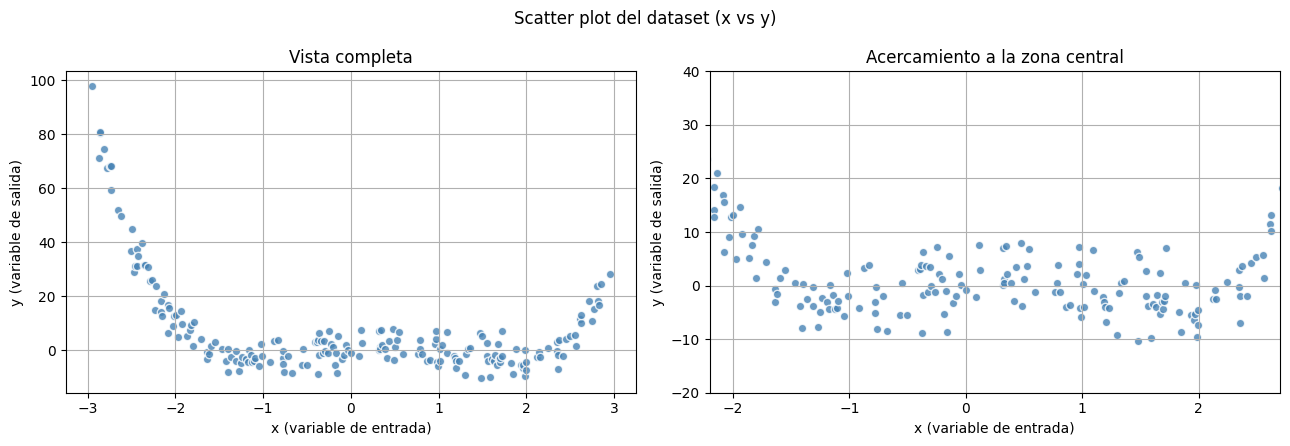

In [26]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))  # Crea una figura con dos paneles lado a lado

ejes[0].scatter(df["x"], df["y"], color="steelblue", edgecolor="white", alpha=0.8)  # Panel izquierdo: dibuja todas las observaciones como puntos azules
ejes[0].set_title("Vista completa")  # Título del panel izquierdo
ejes[0].set_xlabel("x (variable de entrada)")  # Etiqueta del eje horizontal del panel izquierdo
ejes[0].set_ylabel("y (variable de salida)")  # Etiqueta del eje vertical del panel izquierdo

ejes[1].scatter(df["x"], df["y"], color="steelblue", edgecolor="white", alpha=0.8)  # Panel derecho: dibuja las mismas observaciones
ejes[1].set_xlim(-2.2, 2.7)  # Limita el eje horizontal a la zona central de los datos
ejes[1].set_ylim(-20, 40)  # Limita el eje vertical para ampliar la zona donde y toma valores pequeños
ejes[1].set_title("Acercamiento a la zona central")  # Título del panel derecho
ejes[1].set_xlabel("x (variable de entrada)")  # Etiqueta del eje horizontal del panel derecho
ejes[1].set_ylabel("y (variable de salida)")  # Etiqueta del eje vertical del panel derecho

plt.suptitle("Scatter plot del dataset (x vs y)")  # Agrega un título general a toda la figura
plt.tight_layout()  # Ajusta los espacios para que no se encimen los elementos
plt.show()  # Renderiza la figura en el notebook

Observación: los puntos no siguen una recta: $y$ crece muy rápido hacia los extremos y en la zona central la tendencia es mucho más plana, con cambios de dirección sutiles frente al ruido. El scatter plot por sí solo no basta para decidir el grado del polinomio; solo indica que un modelo lineal probablemente será insuficiente y que conviene probar características polinomiales. El grado se elegirá con datos, mediante validación cruzada (sección 3.7).

### 3.5 Preparación de los datos (separación train / test)

Para evaluar honestamente el modelo, los datos se dividen en:
- Entrenamiento (80 %): se usa para ajustar los coeficientes y para elegir el grado (con validación cruzada).
- Prueba (20 %): datos que el modelo nunca vio; se reservan únicamente para la evaluación final (sección 3.9).

Además, scikit-learn exige que las variables de entrada X sean una matriz 2D (filas × columnas).

In [27]:
X = df[["x"]].values  # Extrae la columna x como matriz 2D de forma (200, 1), formato requerido por scikit-learn
y = df["y"].values  # Extrae la columna y como arreglo 1D con la variable objetivo

X_train, X_test, y_train, y_test = train_test_split(  # Divide los datos en subconjuntos de entrenamiento y prueba
    X, y,  # Pasa las entradas X y las salidas y que se van a dividir
    test_size=0.2,  # Reserva el 20 % de los datos para la prueba
    random_state=SEED,  # Fija la semilla para que la división sea siempre la misma
)  # Cierra la llamada a train_test_split

print("Tamaño de entrenamiento:", X_train.shape[0], "observaciones")  # Muestra cuántas observaciones se usarán para entrenar
print("Tamaño de prueba:", X_test.shape[0], "observaciones")  # Muestra cuántas observaciones se usarán para probar

Tamaño de entrenamiento: 160 observaciones
Tamaño de prueba: 40 observaciones


### 3.6 Selección del modelo

El modelo es una regresión polinomial construida con un Pipeline de dos pasos:

1. PolynomialFeatures(degree=n): transforma cada $x$ en el vector $[x, x^2, \dots, x^n]$ (la columna de 1s o *bias* la maneja LinearRegression como intercepto $\beta_0$).
2. LinearRegression(): ajusta los coeficientes $\beta_j$ por mínimos cuadrados ordinarios.

Usar un Pipeline garantiza que la misma transformación se aplique tanto al entrenar como al predecir.

El grado $n$ es un hiperparámetro: no se aprende de los datos al ajustar los coeficientes, hay que elegirlo. Por eso se define una función que construye el pipeline para cualquier grado; así se puede usar tanto para comparar grados (sección 3.7) como para crear el modelo final (sección 3.8).

In [28]:
def crear_modelo(grado):  # Define una función que construye un pipeline (sin entrenar) para el grado indicado
    return Pipeline([  # Devuelve un Pipeline: una secuencia de pasos que se ejecutan en orden
        ("poly", PolynomialFeatures(degree=grado, include_bias=False)),  # Paso 1: genera x, x^2, ..., x^grado (sin columna de unos, el intercepto lo maneja LinearRegression)
        ("lin", LinearRegression()),  # Paso 2: ajusta una regresión lineal por mínimos cuadrados sobre esas características
    ])  # Cierra la definición del Pipeline


print(crear_modelo(4))  # Muestra, como ejemplo, la estructura de un pipeline de grado 4

Pipeline(steps=[('poly', PolynomialFeatures(degree=4, include_bias=False)),
                ('lin', LinearRegression())])


### 3.7 Ajuste del hiperparámetro: elección del grado del polinomio

En la práctica no se conoce el grado real. Se prueban varios grados y se elige el que mejor generaliza, usando validación cruzada de 5 particiones (5-fold CV) sobre el conjunto de entrenamiento (el conjunto de prueba no se toca).

- Si el grado es muy bajo → los errores de entrenamiento y validación son altos: underfitting.
- Si el grado es muy alto → el modelo puede empezar a ajustar el ruido y el error de validación deja de mejorar (o empeora): overfitting.

Además del RMSE promedio, se calcula la desviación estándar del RMSE entre particiones, para saber si las diferencias entre grados son realmente significativas o solo variaciones de muestreo.

Como la consigna exige un polinomio de grado $n > 3$, el grado final se elige entre los candidatos con $n \geq 4$. Se muestran también los grados 1 a 3 para ver el efecto del *underfitting*.

In [29]:
grados = range(1, 11)  # Define los grados a evaluar: del 1 al 10
filas = []  # Lista vacía donde se guardará una fila de resultados por cada grado
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)  # Define la validación cruzada de 5 particiones con mezcla aleatoria reproducible

for g in grados:  # Recorre cada grado candidato
    pipe = crear_modelo(g)  # Construye un pipeline nuevo para este grado
    pipe.fit(X_train, y_train)  # Entrena el pipeline con todo el conjunto de entrenamiento
    rmse_tr = np.sqrt(mean_squared_error(y_train, pipe.predict(X_train)))  # Calcula el RMSE sobre los propios datos de entrenamiento
    scores = -cross_val_score(pipe, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")  # Calcula el RMSE en cada una de las 5 particiones (se invierte el signo porque scikit-learn devuelve el negativo)
    filas.append({  # Guarda los resultados de este grado en un diccionario
        "Grado": g,  # Grado del polinomio evaluado
        "RMSE entrenamiento": rmse_tr,  # Error sobre los datos de entrenamiento
        "RMSE CV (media)": scores.mean(),  # Promedio del RMSE en las 5 particiones
        "RMSE CV (desv. est.)": scores.std(ddof=1),  # Variación del RMSE entre particiones (desviación estándar muestral)
    })  # Cierra el diccionario

resultados = pd.DataFrame(filas)  # Convierte la lista de diccionarios en una tabla
display(resultados.round(3))  # Muestra la tabla con 3 decimales

,Grado,RMSE entrenamiento,RMSE CV (media),RMSE CV (desv. est.)
0,1,16.911,16.999,3.103
1,2,10.712,10.906,1.816
2,3,8.740,9.114,0.303
3,4,3.748,3.827,0.254
4,5,3.745,3.832,0.258
5,6,3.726,3.855,0.239
6,7,3.712,3.858,0.273
7,8,3.708,3.869,0.280
8,9,3.708,3.885,0.257
9,10,3.708,3.915,0.236


Grado seleccionado (menor RMSE medio de validación cruzada con n > 3): 4


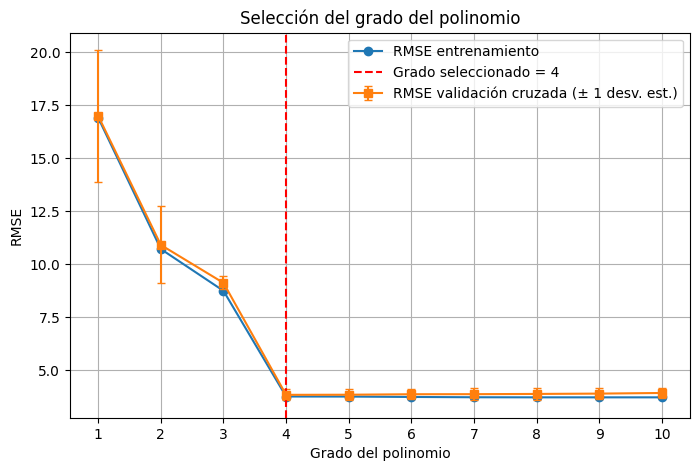

In [30]:
candidatos = resultados[resultados["Grado"] > 3]  # Filtra los grados permitidos por la consigna (n > 3)
mejor_grado = int(candidatos.loc[candidatos["RMSE CV (media)"].idxmin(), "Grado"])  # Elige el grado con menor RMSE medio de validación cruzada entre los candidatos
print("Grado seleccionado (menor RMSE medio de validación cruzada con n > 3):", mejor_grado)  # Imprime el grado elegido

plt.plot(resultados["Grado"], resultados["RMSE entrenamiento"], marker="o", label="RMSE entrenamiento")  # Dibuja el error de entrenamiento en función del grado
plt.errorbar(resultados["Grado"], resultados["RMSE CV (media)"], yerr=resultados["RMSE CV (desv. est.)"], marker="s", capsize=3, label="RMSE validación cruzada (± 1 desv. est.)")  # Dibuja el error de validación cruzada con barras que muestran la variación entre particiones
plt.axvline(mejor_grado, color="red", linestyle="--", label=f"Grado seleccionado = {mejor_grado}")  # Marca con una línea vertical roja el grado elegido
plt.title("Selección del grado del polinomio")  # Agrega el título de la gráfica
plt.xlabel("Grado del polinomio")  # Etiqueta el eje horizontal
plt.ylabel("RMSE")  # Etiqueta el eje vertical
plt.xticks(list(grados))  # Muestra todos los grados enteros en el eje horizontal
plt.legend()  # Muestra la leyenda de las curvas
plt.show()  # Renderiza la gráfica

**Interpretación:**
- Con grados 1 a 3 el error es alto (underfitting): el RMSE de validación baja de ≈ 17 a ≈ 9 y sigue lejos del nivel que alcanzan los grados siguientes.
- Al pasar al grado 4 el RMSE cae a ≈ 3.8 (una mejora muy grande).
- A partir del grado 4 el error de entrenamiento casi no mejora y el de validación deja de disminuir. Las diferencias de RMSE medio entre los grados 4 a 10 son menores a 0.1, mucho menores que la variación entre particiones (≈ 0.25), así que no se puede afirmar que haya una diferencia real entre ellos ni que el sobreajuste sea ya evidente.
- Como el grado 4 tiene el menor RMSE medio y es el más simple entre los equivalentes, se selecciona. Este grado se usará para construir el modelo final en la sección 3.8.

### 3.8 Entrenamiento del modelo final

Ahora se construye el modelo final con el grado seleccionado en la sección 3.7 (mejor_grado) y se entrena con todo el conjunto de entrenamiento. Así, el modelo final depende realmente del resultado de la validación cruzada.

Al llamar fit, PolynomialFeatures genera las características polinomiales y LinearRegression ajusta los coeficientes minimizando la suma de cuadrados de los residuos mediante un solucionador numérico de mínimos cuadrados (para datos densos, scikit-learn usa scipy.linalg.lstsq). Este procedimiento no calcula explícitamente la inversa de $\mathbf{X}^\top\mathbf{X}$, lo que ayuda a mantener la estabilidad numérica.

In [31]:
GRADO = mejor_grado  # Usa el grado elegido por validación cruzada como grado del modelo final
modelo = crear_modelo(GRADO)  # Construye el pipeline final con ese grado
modelo.fit(X_train, y_train)  # Entrena el pipeline: crea las potencias de x y calcula los coeficientes que minimizan el SSE

lin = modelo.named_steps["lin"]  # Obtiene el paso de regresión lineal ya entrenado dentro del pipeline
print("Grado del modelo final:", GRADO)  # Imprime el grado utilizado
print("Intercepto (beta0):", round(lin.intercept_, 4))  # Imprime el término independiente del polinomio
print("Coeficientes (beta1 ... beta" + str(GRADO) + "):", np.round(lin.coef_, 4))  # Imprime los coeficientes de x, x^2, ..., x^GRADO
if GRADO == 4:  # Comprueba si el grado coincide con el del polinomio que generó los datos
    print("Coeficientes con los que se generó el CSV: 1, 2, -4, -1.5, 1.2")  # Muestra los coeficientes verdaderos (solo se conocen porque el dataset es sintético)

Grado del modelo final: 4
Intercepto (beta0): 1.5056
Coeficientes (beta1 ... beta4): [ 2.6313 -4.7815 -1.5429  1.3121]
Coeficientes con los que se generó el CSV: 1, 2, -4, -1.5, 1.2


Comparación con la solución analítica (sección 2): con los mismos datos de entrenamiento se calculan los coeficientes con (a) la ecuación normal, (b) np.linalg.lstsq y (c) scikit-learn, y se verifica que coinciden.

> Los coeficientes estimados no son exactamente iguales a los que generaron los datos. Es lo esperado: los datos contienen ruido y el modelo estima los coeficientes a partir de una muestra finita; el objetivo es una buena estimación, no recuperar los valores exactos.

In [32]:
X_vand = np.vander(X_train.ravel(), N=GRADO + 1, increasing=True)  # Construye la matriz de Vandermonde [1, x, ..., x^GRADO] con los datos de entrenamiento
beta_normal = np.linalg.solve(X_vand.T @ X_vand, X_vand.T @ y_train)  # Resuelve las ecuaciones normales (X^T X) beta = X^T y
beta_lstsq, *_ = np.linalg.lstsq(X_vand, y_train, rcond=None)  # Resuelve el problema de mínimos cuadrados directamente, sin formar X^T X
beta_sklearn = np.concatenate(([lin.intercept_], lin.coef_))  # Une el intercepto y los coeficientes de scikit-learn en un solo vector

comparacion = pd.DataFrame({  # Crea una tabla para comparar los tres métodos
    "Coeficiente": [f"beta{i}" for i in range(GRADO + 1)],  # Nombres beta0, beta1, ..., betaGRADO
    "Ecuación normal": beta_normal,  # Coeficientes obtenidos con la ecuación normal
    "np.linalg.lstsq": beta_lstsq,  # Coeficientes obtenidos con lstsq
    "scikit-learn": beta_sklearn,  # Coeficientes obtenidos con LinearRegression
})  # Cierra la creación de la tabla
display(comparacion.round(5))  # Muestra la tabla con 5 decimales
print("¿Coinciden los tres métodos?", np.allclose(beta_normal, beta_sklearn) and np.allclose(beta_lstsq, beta_sklearn))  # Verifica numéricamente que los tres vectores sean prácticamente iguales

,Coeficiente,Ecuación normal,np.linalg.lstsq,scikit-learn
0,beta0,1.50556,1.50556,1.50556
1,beta1,2.63127,2.63127,2.63127
2,beta2,-4.78153,-4.78153,-4.78153
3,beta3,-1.54292,-1.54292,-1.54292
4,beta4,1.31212,1.31212,1.31212


¿Coinciden los tres métodos? True


### 3.9 Evaluación del modelo (métricas)

Ahora sí se usa el conjunto de prueba, que no participó ni en el entrenamiento ni en la elección del grado. Se calculan también las métricas en entrenamiento para comparar, y se añade una recta (grado 1) como modelo de referencia, para cuantificar cuánto mejora el modelo polinomial.

In [33]:
y_pred_train = modelo.predict(X_train)  # Genera las predicciones del modelo final sobre los datos de entrenamiento
y_pred_test = modelo.predict(X_test)  # Genera las predicciones del modelo final sobre los datos de prueba (no vistos)

recta = crear_modelo(1)  # Construye el modelo de referencia: un polinomio de grado 1 (una recta)
recta.fit(X_train, y_train)  # Entrena la recta con los mismos datos de entrenamiento
y_pred_recta = recta.predict(X_test)  # Predice con la recta sobre los mismos datos de prueba


def evaluar(y_real, y_pred, n_features):  # Define una función que calcula todas las métricas de regresión
    mae = mean_absolute_error(y_real, y_pred)  # Calcula el error absoluto medio
    mse = mean_squared_error(y_real, y_pred)  # Calcula el error cuadrático medio
    rmse = np.sqrt(mse)  # Calcula la raíz del MSE para volver a las unidades de y
    r2 = r2_score(y_real, y_pred)  # Calcula el coeficiente de determinación R^2
    m_obs = len(y_real)  # Obtiene el número de observaciones evaluadas
    r2_adj = 1 - (1 - r2) * (m_obs - 1) / (m_obs - n_features - 1)  # Calcula el R^2 ajustado que penaliza el número de variables
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "R2 ajustado": r2_adj}  # Devuelve las métricas en un diccionario


metricas = pd.DataFrame({  # Crea una tabla comparativa de métricas
    f"Polinomial grado {GRADO} (entrenamiento)": evaluar(y_train, y_pred_train, GRADO),  # Métricas del modelo final con los datos de entrenamiento
    f"Polinomial grado {GRADO} (prueba)": evaluar(y_test, y_pred_test, GRADO),  # Métricas del modelo final con los datos de prueba
    "Recta, grado 1 (prueba)": evaluar(y_test, y_pred_recta, 1),  # Métricas del modelo de referencia con los datos de prueba
})  # Cierra la creación de la tabla
display(metricas.round(4))  # Muestra la tabla con 4 decimales

,Polinomial grado 4 (entrenamiento),Polinomial grado 4 (prueba),"Recta, grado 1 (prueba)"
MAE,3.0654,3.5714,10.0474
MSE,14.0467,22.2599,149.9749
RMSE,3.7479,4.7180,12.2464
R2,0.9633,0.8747,0.1558
R2 ajustado,0.9624,0.8604,0.1336


Interpretación de las métricas:
- En los datos de prueba el modelo polinomial obtiene un $R^2$ de ≈ 0.87 y un RMSE de ≈ 4.7, frente a un RMSE de ≈ 12.2 de la recta: el modelo polinomial reduce el error de prueba a menos de la mitad del error de la recta.
- El error de prueba (≈ 4.7) es mayor que el de entrenamiento (≈ 3.7) y que el de validación cruzada (≈ 3.8). No parece haber un sobreajuste severo, pero conviene reconocer esa diferencia en lugar de ignorarla.
- Con solo 40 observaciones de prueba, las métricas dependen bastante de qué puntos cayeron en ese conjunto; además, los coeficientes se estiman con incertidumbre. El nivel de error es del orden de la desviación estándar del ruido que se usó al generar los datos (4), por lo que es un resultado razonable, aunque no se puede atribuir toda la diferencia a un solo factor. Los valores exactos cambiarían con otra semilla o otra partición.
- Recuerda que $R^2$ sobre datos de prueba puede ser negativo si el modelo predice peor que la media; aquí no es el caso.

### 3.10 Visualización de la curva ajustada y análisis de residuos

Se compara la curva ajustada contra la curva real (conocida solo porque el dataset es sintético; en un problema real no se dispone de ella) y contra la recta de referencia. El segundo panel amplía la zona central.

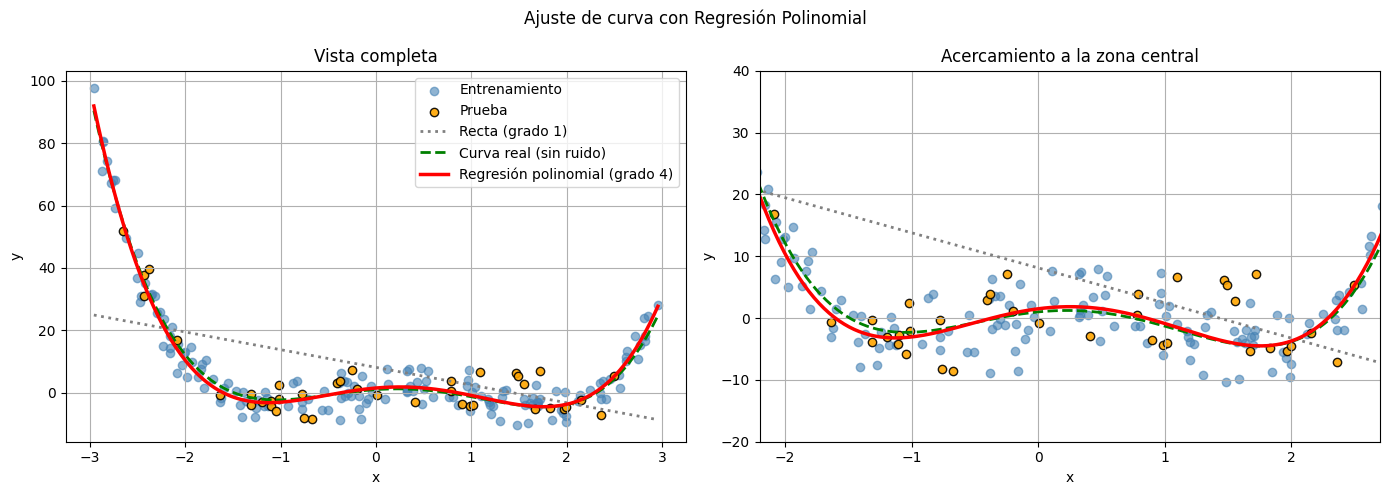

In [34]:
x_curva = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)  # Crea 300 puntos x equiespaciados (matriz 2D) para dibujar curvas suaves
y_curva = modelo.predict(x_curva)  # Calcula la curva ajustada por el modelo final en esos puntos
y_real = 1 + 2 * x_curva - 4 * x_curva**2 - 1.5 * x_curva**3 + 1.2 * x_curva**4  # Calcula la curva verdadera sin ruido (conocida por ser un dataset sintético)
y_recta = recta.predict(x_curva)  # Calcula la recta de referencia en los mismos puntos

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))  # Crea una figura con dos paneles lado a lado

for k, eje in enumerate(ejes):  # Recorre los dos paneles para dibujar las mismas series en ambos
    eje.scatter(X_train, y_train, color="steelblue", alpha=0.6, label="Entrenamiento")  # Dibuja los puntos de entrenamiento en azul
    eje.scatter(X_test, y_test, color="orange", edgecolor="black", alpha=0.9, label="Prueba")  # Dibuja los puntos de prueba en naranja con borde negro
    eje.plot(x_curva, y_recta, color="gray", linestyle=":", linewidth=2, label="Recta (grado 1)")  # Dibuja la recta de referencia con línea punteada gris
    eje.plot(x_curva, y_real, color="green", linestyle="--", linewidth=2, label="Curva real (sin ruido)")  # Dibuja la curva verdadera con línea discontinua verde
    eje.plot(x_curva, y_curva, color="red", linewidth=2.5, label=f"Regresión polinomial (grado {GRADO})")  # Dibuja la curva ajustada con línea roja gruesa
    eje.set_xlabel("x")  # Etiqueta el eje horizontal
    eje.set_ylabel("y")  # Etiqueta el eje vertical

ejes[0].set_title("Vista completa")  # Título del panel izquierdo
ejes[0].legend()  # Muestra la leyenda solo en el panel izquierdo
ejes[1].set_xlim(-2.2, 2.7)  # Limita el eje horizontal del panel derecho a la zona central
ejes[1].set_ylim(-20, 40)  # Limita el eje vertical del panel derecho para ampliar esa zona
ejes[1].set_title("Acercamiento a la zona central")  # Título del panel derecho

plt.suptitle("Ajuste de curva con Regresión Polinomial")  # Agrega un título general a la figura
plt.tight_layout()  # Ajusta los espacios para que no se encimen los elementos
plt.show()  # Renderiza la figura

#### Análisis de residuos
Los residuos ($y - \hat{y}$) sobre el conjunto de prueba se examinan desde cuatro ángulos: contra las predicciones, contra $x$, su histograma y un gráfico Q-Q (que compara sus cuantiles con los de una distribución normal).

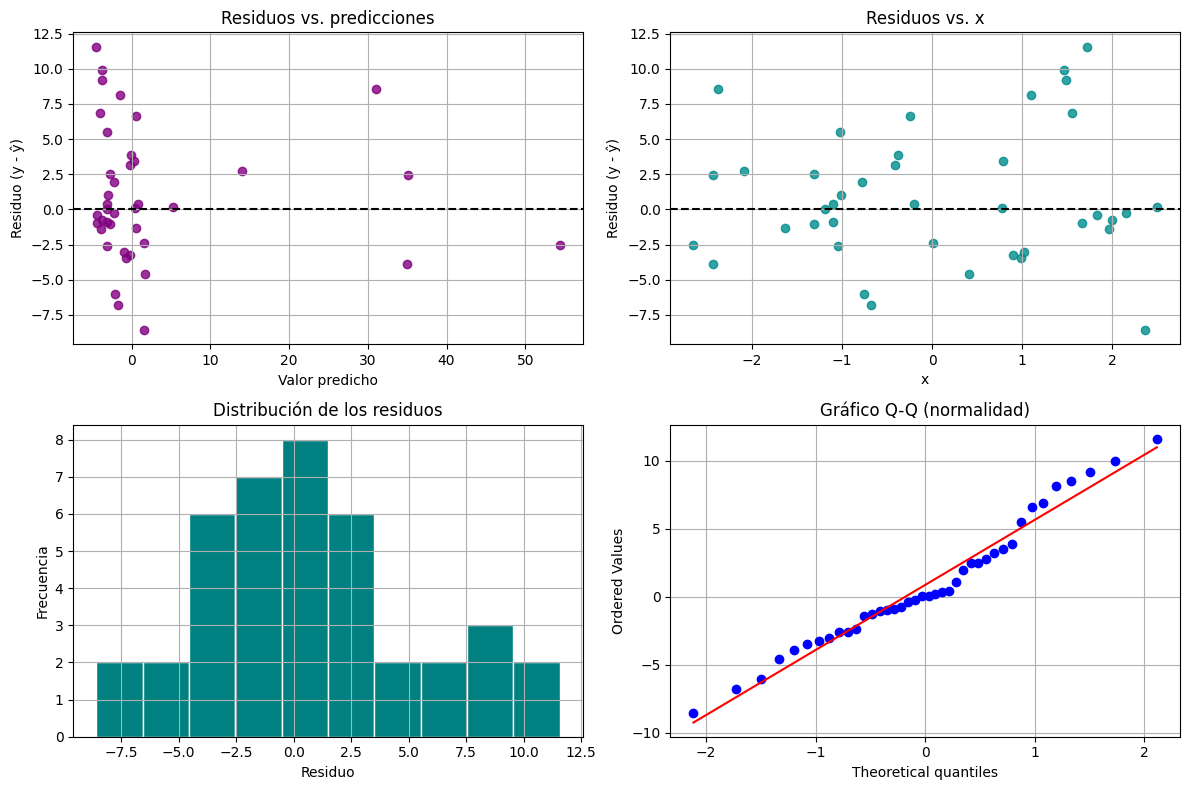

In [35]:
residuos = y_test - y_pred_test  # Calcula los residuos (valor real menos valor predicho) sobre el conjunto de prueba

fig, ejes = plt.subplots(2, 2, figsize=(12, 8))  # Crea una figura con 4 gráficas (2 filas x 2 columnas)

ejes[0, 0].scatter(y_pred_test, residuos, color="purple", alpha=0.8)  # Grafica los residuos contra los valores predichos
ejes[0, 0].axhline(0, color="black", linestyle="--")  # Dibuja la línea de residuo cero como referencia
ejes[0, 0].set_title("Residuos vs. predicciones")  # Título de la primera gráfica
ejes[0, 0].set_xlabel("Valor predicho")  # Etiqueta del eje horizontal
ejes[0, 0].set_ylabel("Residuo (y - ŷ)")  # Etiqueta del eje vertical

ejes[0, 1].scatter(X_test.ravel(), residuos, color="darkcyan", alpha=0.8)  # Grafica los residuos contra la variable de entrada x
ejes[0, 1].axhline(0, color="black", linestyle="--")  # Dibuja la línea de residuo cero como referencia
ejes[0, 1].set_title("Residuos vs. x")  # Título de la segunda gráfica
ejes[0, 1].set_xlabel("x")  # Etiqueta del eje horizontal
ejes[0, 1].set_ylabel("Residuo (y - ŷ)")  # Etiqueta del eje vertical

ejes[1, 0].hist(residuos, bins=10, color="teal", edgecolor="white")  # Dibuja el histograma de los residuos con 10 barras
ejes[1, 0].set_title("Distribución de los residuos")  # Título de la tercera gráfica
ejes[1, 0].set_xlabel("Residuo")  # Etiqueta del eje horizontal
ejes[1, 0].set_ylabel("Frecuencia")  # Etiqueta del eje vertical

stats.probplot(residuos, dist="norm", plot=ejes[1, 1])  # Dibuja el gráfico Q-Q: cuantiles de los residuos contra los de una normal teórica
ejes[1, 1].set_title("Gráfico Q-Q (normalidad)")  # Título de la cuarta gráfica

plt.tight_layout()  # Ajusta los espacios para que no se encimen los elementos
plt.show()  # Renderiza las cuatro gráficas

Interpretación de los residuos: si el modelo es adecuado, los residuos deben verse repartidos al azar alrededor de 0, sin curvaturas ni embudos, ni respecto a las predicciones ni respecto a $x$. En estas gráficas no se observa una curvatura o un embudo evidente, lo cual es coherente con un ajuste adecuado. Sí se nota una ligera asimetría: hay algunos residuos positivos algo mayores (hasta ≈ 11) que los negativos (hasta ≈ −8), y en el gráfico Q-Q los puntos se separan un poco de la recta en el extremo superior. Con solo 40 observaciones esto no es concluyente, pero conviene mencionarlo en lugar de ignorarlo.

Conviene ser prudente: con solo 40 residuos, el histograma y el gráfico Q-Q son aproximados y no permiten demostrar que los residuos sean normales, ni que "solo quede ruido aleatorio". Sirven como comprobación visual de que no hay problemas graves.

### 3.11 Predicción con datos nuevos

Una vez validado, el modelo se usa para predecir $y$ en valores de $x$ que no estaban en el dataset. Los valores elegidos están dentro del rango de entrenamiento (de −3 a 3): los polinomios pueden comportarse de forma errática al extrapolar fuera de ese rango, así que no se recomienda predecir ahí.

In [36]:
x_nuevos = np.array([[-2.5], [0.0], [1.5], [2.8]])  # Define 4 valores nuevos de x (matriz 2D, un valor por fila) dentro del rango de entrenamiento
y_nuevos = modelo.predict(x_nuevos)  # Predice la salida y para cada valor nuevo con el modelo final entrenado

for xi, yi in zip(x_nuevos.ravel(), y_nuevos):  # Recorre cada par (x, y predicha)
    print(f"Para x = {xi:5.2f}  ->  y predicha = {yi:8.3f}")  # Imprime la predicción con formato alineado

Para x = -2.50  ->  y predicha =   40.406
Para x =  0.00  ->  y predicha =    1.506
Para x =  1.50  ->  y predicha =   -3.871
Para x =  2.80  ->  y predicha =   18.166


---
## 4. Conclusiones

1. La Regresión Polinomial permite ajustar curvas no lineales usando el mismo método de mínimos cuadrados de la regresión lineal, porque el modelo es lineal en los parámetros $\beta_j$.
2. El scatter plot y el EDA indicaron que una recta sería insuficiente, y la comparación numérica lo confirmó: el RMSE de prueba de la recta (≈ 12.2) es más del doble que el del polinomio (≈ 4.7).
3. La solución analítica $\hat{\boldsymbol{\beta}} = (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$, np.linalg.lstsq y scikit-learn coincidieron, validando el modelo matemático. En la práctica se prefieren los solucionadores numéricos de mínimos cuadrados, más estables que formar la inversa.
4. La validación cruzada permitió elegir un grado con bajo error de validación (n = 4 > 3) y redujo el riesgo de escoger un modelo innecesariamente complejo. Las diferencias entre los grados 4 y superiores son menores que la variación entre particiones, por lo que se eligió el más simple.
5. Los resultados de prueba ($R^2$ ≈ 0.87, RMSE ≈ 4.7) indican una generalización razonablemente buena para este dataset sintético, con la salvedad de que el error de prueba es algo mayor que el de entrenamiento y de que el conjunto de prueba es pequeño (40 observaciones).
6. Limitaciones: los polinomios de grado alto pueden oscilar mucho al extrapolar fuera del rango de entrenamiento y son sensibles a valores atípicos y al mal condicionamiento numérico; en esos casos conviene escalar las variables o usar regularización (Ridge/Lasso).

---
## 5. Referencias
- Six Sigma Material. *Regression*. https://www.six-sigma-material.com/Regression.html
- scikit-learn. *PolynomialFeatures*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html
- scikit-learn. *LinearRegression*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
- scikit-learn. *Linear Models: Ordinary Least Squares*. https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares
- scikit-learn. *Cross-validation* y *Metrics and scoring*. https://scikit-learn.org/stable/modules/cross_validation.html
- Hastie, T., Tibshirani, R., Friedman, J. *The Elements of Statistical Learning* (2.ª ed.), cap. 3: Linear Methods for Regression. Springer, 2009.
- James, G., Witten, D., Hastie, T., Tibshirani, R. *An Introduction to Statistical Learning*, cap. 3 y 5. Springer.